# ASL from Hand Landmarks

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"
LABEL_MAP = {letter: index for index, letter in enumerate(LETTERS)}
INV_LABEL_MAP = {index: letter for index, letter in enumerate(LETTERS)}

# Load data

landmarks_df = pd.read_csv(
    "../data/preprocessed/handlandmarks_d01megadataset_v2.csv")

In [2]:
landmarks_df.head()

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,57,58,59,60,61,62,letter_index,dataset,user,image_path
0,0,0.0,0.0,0.0,0.542590,-0.123036,-0.099435,0.928113,-0.550039,-0.125472,...,-0.263595,-0.677534,-0.352767,-0.247788,-0.623774,-0.302888,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...
1,1,0.0,0.0,0.0,0.531275,-0.145492,-0.093864,0.904784,-0.576911,-0.117419,...,-0.298376,-0.715572,-0.312834,-0.269324,-0.616285,-0.254807,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...
2,2,0.0,0.0,0.0,0.549522,-0.172554,-0.104654,0.933872,-0.542998,-0.128132,...,-0.286491,-0.950998,-0.240545,-0.256834,-0.785509,-0.175398,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...
3,3,0.0,0.0,0.0,0.058595,-0.293575,0.038483,0.351997,-0.601378,0.112757,...,0.900283,-1.290702,-0.077911,0.786880,-1.463242,-0.067739,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...
4,4,0.0,0.0,0.0,0.058595,-0.293575,0.038483,0.351997,-0.601378,0.112757,...,0.900283,-1.290702,-0.077911,0.786880,-1.463242,-0.067739,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...


In [3]:
landmarks_df["letter_index"].nunique()

24

In [4]:
landmarks_df["letter_index"].value_counts().sort_index()

letter_index
0     7340
1     7340
2     7340
3     7340
4     4340
5     7340
6     7340
7     7340
8     8077
9     6758
10    7764
11    4194
12    5238
13    8564
14    3836
15    4860
16    4808
17    3644
18    4346
19    4514
20    5196
21    3356
22    3600
23    3724
Name: count, dtype: int64

In [5]:
# No hand detected
landmarks_df.loc[landmarks_df["image_path"]=="data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg"]

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,57,58,59,60,61,62,letter_index,dataset,user,image_path
7,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...


In [6]:
landmarks_df.isna().sum()

Unnamed: 0           0
0                27611
1                27611
2                27611
3                27611
                 ...  
62               27611
letter_index         0
dataset              0
user            131719
image_path           0
Length: 68, dtype: int64

In [7]:
# No hand detected
landmarks_df["no_hand"] = landmarks_df['0'].isna()

# Letter
landmarks_df["letter"] = landmarks_df["letter_index"].replace(INV_LABEL_MAP)

landmarks_df.head()

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,59,60,61,62,letter_index,dataset,user,image_path,no_hand,letter
0,0,0.0,0.0,0.0,0.542590,-0.123036,-0.099435,0.928113,-0.550039,-0.125472,...,-0.352767,-0.247788,-0.623774,-0.302888,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A
1,1,0.0,0.0,0.0,0.531275,-0.145492,-0.093864,0.904784,-0.576911,-0.117419,...,-0.312834,-0.269324,-0.616285,-0.254807,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A
2,2,0.0,0.0,0.0,0.549522,-0.172554,-0.104654,0.933872,-0.542998,-0.128132,...,-0.240545,-0.256834,-0.785509,-0.175398,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A
3,3,0.0,0.0,0.0,0.058595,-0.293575,0.038483,0.351997,-0.601378,0.112757,...,-0.077911,0.786880,-1.463242,-0.067739,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A
4,4,0.0,0.0,0.0,0.058595,-0.293575,0.038483,0.351997,-0.601378,0.112757,...,-0.077911,0.786880,-1.463242,-0.067739,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A


In [12]:
landmarks_df["letter"].value_counts().sort_index()

letter
A    7340
B    7340
C    7340
D    7340
E    4340
F    7340
G    7340
H    7340
I    8077
K    6758
L    7764
M    4194
N    5238
O    8564
P    3836
Q    4860
R    4808
S    3644
T    4346
U    4514
V    5196
W    3356
X    3600
Y    3724
Name: count, dtype: int64

In [13]:
# Count images per dataset where no hand was detected
landmarks_df.loc[landmarks_df["no_hand"], "dataset"].value_counts()

dataset
A03_kaggle_asl        27587
A04_mandalay_aslhg       20
B02_aslyset               4
Name: count, dtype: int64

In [14]:
# Count images with hands per dataset
landmarks_df.loc[~landmarks_df["no_hand"], "dataset"].value_counts()

dataset
A03_kaggle_asl           80132
A04_mandalay_aslhg       23980
B02_aslyset               4796
B01_original_aslmnist     1680
Name: count, dtype: int64

In [15]:
# Count images with hands per dataset and user
landmarks_df.loc[~landmarks_df["no_hand"]
                 ].groupby(["dataset", "user"])[["image_path"]].nunique()

image_path
dataset               user               
B01_original_aslmnist user_10         240
                      user_3          240
                      user_4          240
                      user_5          240
                      user_6          240
                      user_7          240
                      user_9          240
B02_aslyset           User1          1198
                      User2          1198
                      User3          1200
                      User4          1200

In [16]:
# Stratify by dataset and letter

hand_bool = ~landmarks_df["no_hand"]

# For datasets with users, keep one user for validation and another for testing
landmarks_df["train"] = False
landmarks_df["val"] = False
landmarks_df["test"] = False

landmarks_df.loc[hand_bool & (landmarks_df["user"]=="User3"), "val"] = True
landmarks_df.loc[hand_bool & (landmarks_df["user"]=="user_10"), "val"] = True

landmarks_df.loc[hand_bool & (landmarks_df["user"]=="User4"), "test"] = True
landmarks_df.loc[hand_bool & (landmarks_df["user"]=="user_9"), "test"] = True

landmarks_df.loc[(hand_bool) &
    (landmarks_df["dataset"] == "B02_aslyset") &
    (~ landmarks_df["val"]) &
    (~landmarks_df["test"]), "train"] = True
landmarks_df.loc[(hand_bool)&
                 (landmarks_df["dataset"] == "B01_original_aslmnist") &
                 (~ landmarks_df["val"]) &
                 (~landmarks_df["test"]), "train"] = True

# For other datasets, take 80% for training, 10% for validation and 10% for testing

# A03 Kaggle ASL
indexes_a03 = landmarks_df.loc[
    hand_bool &
    (landmarks_df["dataset"]=="A03_kaggle_asl")].index.values
indexes_a03_train, indexes_a03_other = train_test_split(
    indexes_a03,
    train_size=0.8,
    stratify=landmarks_df.iloc[indexes_a03]["letter"].values,
    random_state=42
)
indexes_a03_val, indexes_a03_test = train_test_split(
    indexes_a03_other,
    train_size=0.5,
    stratify=landmarks_df.iloc[indexes_a03_other]["letter"].values,
    random_state=42)
landmarks_df.loc[indexes_a03_train, "train"] = True
landmarks_df.loc[indexes_a03_val, "val"] = True
landmarks_df.loc[indexes_a03_test, "test"] = True

# A04 Mandalay ASLHG
indexes_a04 = landmarks_df.loc[hand_bool &
    (landmarks_df["dataset"]=="A04_mandalay_aslhg")
    ].index.values
indexes_a04_train, indexes_a04_other = train_test_split(
    indexes_a04,
    train_size=0.8,
    stratify=landmarks_df.iloc[indexes_a04]["letter"].values,
    random_state=42
)
indexes_a04_val, indexes_a04_test = train_test_split(
    indexes_a04_other,
    train_size=0.5,
    stratify=landmarks_df.iloc[indexes_a04_other]["letter"].values,
    random_state=42
)
landmarks_df.loc[indexes_a04_train, "train"] = True
landmarks_df.loc[indexes_a04_val, "val"] = True
landmarks_df.loc[indexes_a04_test, "test"] = True

In [17]:
landmarks_df.groupby(["dataset"])[["train", "val", "test"]].sum()

,train,val,test
dataset,,,
A03_kaggle_asl,64105,8013,8014
A04_mandalay_aslhg,19184,2398,2398
B01_original_aslmnist,1200,240,240
B02_aslyset,2396,1200,1200


In [18]:
landmarks_df.query("val")

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,62,letter_index,dataset,user,image_path,no_hand,letter,train,val,test
1,1,0.0,0.0,0.0,0.531275,-0.145492,-0.093864,0.904784,-0.576911,-0.117419,...,-0.254807,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A,False,True,False
4,4,0.0,0.0,0.0,0.058595,-0.293575,0.038483,0.351997,-0.601378,0.112757,...,-0.067739,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A,False,True,False
46,46,0.0,0.0,0.0,0.535995,-0.187098,-0.133792,0.930325,-0.532216,-0.168769,...,-0.150632,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A,False,True,False
89,89,0.0,0.0,0.0,0.552880,-0.145129,-0.113624,0.958565,-0.500301,-0.142534,...,-0.181634,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A,False,True,False
156,156,0.0,0.0,0.0,0.531747,-0.185936,-0.144989,0.953278,-0.497712,-0.187950,...,-0.128347,0,A03_kaggle_asl,NaN,data/dataset/D01_megadataset/A/A03_kaggle_asl_...,False,A,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138144,138144,0.0,0.0,0.0,0.402823,-0.218709,-0.160323,0.643490,-0.717181,-0.209233,...,-0.568230,23,B02_aslyset,User3,data/dataset/D01_megadataset/Y/B02_aslyset__Us...,False,Y,False,True,False
138145,138145,0.0,0.0,0.0,0.315694,-0.348374,-0.070020,0.402251,-0.836123,-0.072140,...,-0.335732,23,B02_aslyset,User3,data/dataset/D01_megadataset/Y/B02_aslyset__Us...,False,Y,False,True,False
138146,138146,0.0,0.0,0.0,0.324482,-0.337311,-0.116809,0.417364,-0.868319,-0.128831,...,-0.229359,23,B02_aslyset,User3,data/dataset/D01_megadataset/Y/B02_aslyset__Us...,False,Y,False,True,False
138147,138147,0.0,0.0,0.0,0.335556,-0.375338,-0.110328,0.423336,-0.929852,-0.112079,...,-0.183907,23,B02_aslyset,User3,data/dataset/D01_megadataset/Y/B02_aslyset__Us...,False,Y,False,True,False


In [34]:
import numpy as np
# shuffle training data
np_random_seed = np.random.default_rng(42)
train_indexes = np_random_seed.permutation(landmarks_df.query("train").index.values)
X_train = landmarks_df.loc[train_indexes].iloc[:, 1:64]
y_train = landmarks_df.loc[train_indexes]["letter_index"]
print(X_train.columns)

# Validation
val_indexes = landmarks_df.query("val").index.values
X_val = landmarks_df.loc[val_indexes].iloc[:, 1:64]
y_val = landmarks_df.loc[val_indexes]["letter_index"]

# Validation
test_indexes = landmarks_df.query("test").index.values
X_test = landmarks_df.loc[test_indexes].iloc[:, 1:64]
y_test = landmarks_df.loc[test_indexes]["letter_index"]

len(train_indexes), len(val_indexes), len(test_indexes)

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36',
       '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48',
       '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60',
       '61', '62'],
      dtype='str')


(86885, 11851, 11852)

In [20]:
import matplotlib.pyplot as plt
from handspell.model_landmarks import find_images, create_landmarker, read_rgb, get_features


MediaPipe model: ../models/hand_landmarker.task
13: detected (data/dataset/D01_megadataset/O/A03_kaggle_asl__O373.jpg)
2: detected (data/dataset/D01_megadataset/C/A03_kaggle_asl__769.jpg)
1: detected (data/dataset/D01_megadataset/B/A03_kaggle_asl__181_copy.jpg)
4: detected (data/dataset/D01_megadataset/E/A03_kaggle_asl__hand5_e_dif_seg_5_cropped.jpeg)
18: detected (data/dataset/D01_megadataset/T/A03_kaggle_asl__T2952.jpg)
13: detected (data/dataset/D01_megadataset/O/A04_mandalay_aslhg__P2_O_184.jpg)


W0000 00:00:1792534163.998099 6949864 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792534164.010061 6949864 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


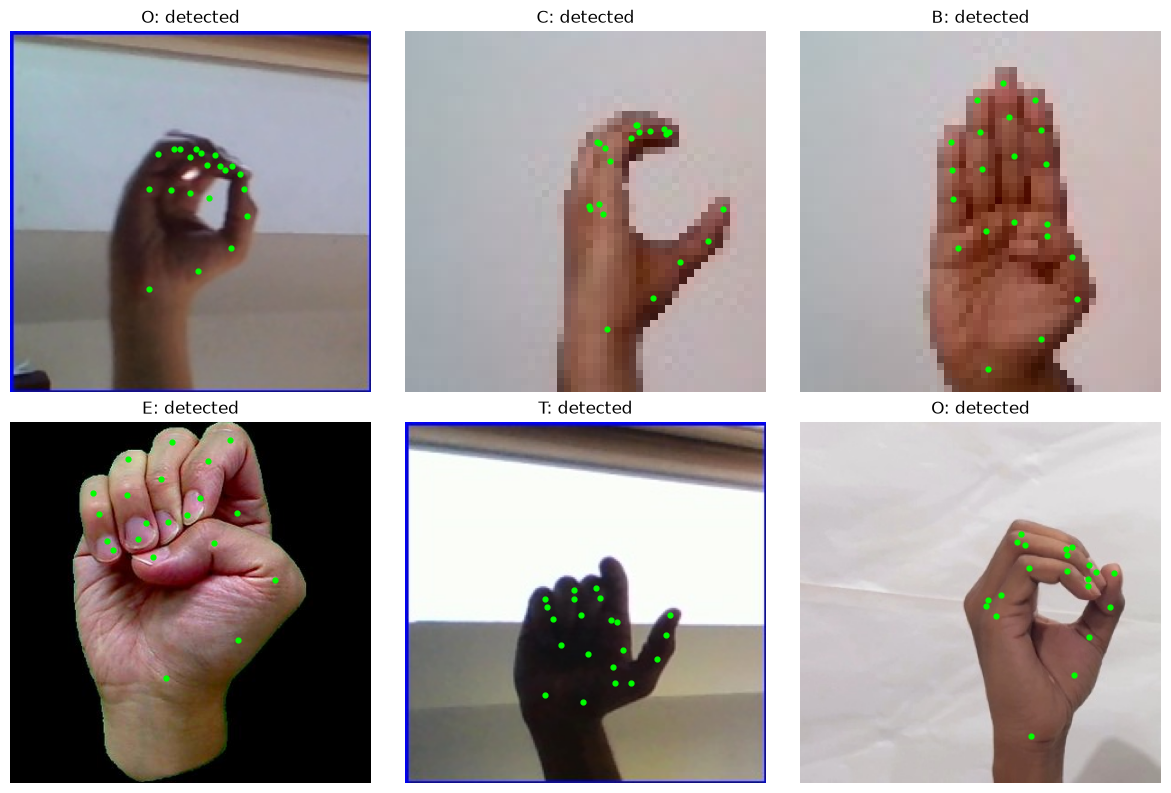

In [35]:
paths = landmarks_df["image_path"]
labels = landmarks_df["letter"]

sample_indices = np_random_seed.choice(
    len(paths),
    size=min(6, len(paths)),
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

with create_landmarker() as landmarker:
    for ax, index in zip(axes.flat, sample_indices):
        path = paths[index]

        rgb = read_rgb('../'+paths[index])
        _, landmarks = get_features(rgb, landmarker)

        ax.imshow(rgb)

        if landmarks:
            height, width = rgb.shape[:2]
            ax.scatter(
                [point.x * width for point in landmarks],
                [point.y * height for point in landmarks],
                s=12,
                c="lime",
            )
            status = "detected"
        else:
            status = "NO HAND"

        ax.set_title(f"{labels[index]}: {status}")
        print(f"{LABEL_MAP[labels[index]]}: {status} ({path})")

plt.tight_layout()
plt.show()

In [ ]:
train_ok = ~landmarks_df["no_hand"]
failures = landmarks_df.loc[~train_ok, "image_path"]

print(f"Training hand detection: {train_ok.mean():.1%}")
print("First loading/detection failures:\n", failures[:3].values)

# All 24 classes must have usable training examples.
missing = set(LABEL_MAP.values()) - set(y_train)

if missing:
    raise ValueError(
        f"No usable training images for: {[
            LABEL_MAP[el] for el in sorted(missing)]}"
    )

Training hand detection: 80.0%
First loading/detection failures:
 7     data/dataset/D01_megadataset/A/A03_kaggle_asl_...
8     data/dataset/D01_megadataset/A/A03_kaggle_asl_...
11    data/dataset/D01_megadataset/A/A03_kaggle_asl_...
Name: image_path, dtype: str


In [37]:
y_train.value_counts().sort_index()

letter_index
0     3935
1     5164
2     4783
3     5368
4     2813
5     5695
6     5299
7     5271
8     5503
9     4883
10    5479
11    2486
12    2140
13    3107
14    1878
15    1448
16    2945
17    2230
18    2748
19    2755
20    3711
21    2602
22    2091
23    2551
Name: count, dtype: int64

In [30]:
from xgboost import XGBClassifier

In [40]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=24,
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="merror",
    random_state=42,
    n_jobs=4,
)

In [41]:
classifier.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
)

[0]	validation_0-merror:0.29593	validation_1-merror:0.33356
[1]	validation_0-merror:0.16192	validation_1-merror:0.19830
[2]	validation_0-merror:0.10024	validation_1-merror:0.13830
[3]	validation_0-merror:0.07520	validation_1-merror:0.11400
[4]	validation_0-merror:0.06707	validation_1-merror:0.10438
[5]	validation_0-merror:0.06072	validation_1-merror:0.09611
[6]	validation_0-merror:0.05667	validation_1-merror:0.09223
[7]	validation_0-merror:0.05439	validation_1-merror:0.08928
[8]	validation_0-merror:0.05093	validation_1-merror:0.08573
[9]	validation_0-merror:0.04957	validation_1-merror:0.08362
[10]	validation_0-merror:0.04790	validation_1-merror:0.08143
[11]	validation_0-merror:0.04633	validation_1-merror:0.08101
[12]	validation_0-merror:0.04485	validation_1-merror:0.07957
[13]	validation_0-merror:0.04414	validation_1-merror:0.07712
[14]	validation_0-merror:0.04283	validation_1-merror:0.07636
[15]	validation_0-merror:0.04131	validation_1-merror:0.07468
[16]	validation_0-merror:0.04042	v

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [43]:
y_pred_train = classifier.predict(X_train)
y_pred_val = classifier.predict(X_val)
y_pred_test = classifier.predict(X_test)

print(f"Train Images: {len(y_pred_train)}")
print(f"Train accuracy: {(y_pred_train == y_train).mean():.2%}")
print()
print(f"Val Images: {len(y_pred_val)}")
print(f"Val accuracy: {(y_pred_val == y_val).mean():.2%}")
print()
print(f"Test Images: {len(y_pred_test)}")
print(f"Test accuracy: {(y_pred_test == y_pred_test).mean():.2%}")
print()

Train Images: 86885
Train accuracy: 99.98%

Val Images: 11851
Val accuracy: 97.36%

Test Images: 11852
Test accuracy: 100.00%



In [44]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_val,
    labels=np.arange(24),
    target_names=list(LETTERS),
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

           A      0.974     0.998     0.986       533
           B      1.000     1.000     1.000       686
           C      0.968     0.986     0.977       639
           D      0.942     0.989     0.965       712
           E      0.977     0.982     0.980       393
           F      1.000     1.000     1.000       753
           G      0.962     0.997     0.979       704
           H      0.993     0.957     0.975       701
           I      0.982     1.000     0.991       729
           K      0.998     1.000     0.999       651
           L      1.000     0.978     0.989       726
           M      0.809     0.977     0.885       352
           N      0.958     0.958     0.958       309
           O      0.965     0.951     0.958       430
           P      0.987     0.841     0.908       276
           Q      0.955     0.946     0.950       222
           R      0.977     0.944     0.960       409
           S      0.971    

In [45]:
print(classification_report(
    y_test,
    y_pred_test,
    labels=np.arange(24),
    target_names=list(LETTERS),
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

           A      0.985     1.000     0.993       533
           B      1.000     0.999     0.999       687
           C      0.971     0.981     0.976       639
           D      0.968     0.982     0.975       713
           E      0.869     0.995     0.928       393
           F      0.999     0.993     0.996       754
           G      0.987     0.977     0.982       704
           H      0.996     0.979     0.987       700
           I      0.996     0.992     0.994       729
           K      1.000     0.992     0.996       652
           L      1.000     0.997     0.999       726
           M      0.929     0.972     0.950       352
           N      0.993     0.900     0.944       309
           O      0.957     0.974     0.965       430
           P      1.000     0.938     0.968       276
           Q      0.991     0.986     0.989       222
           R      0.980     0.973     0.977       409
           S      0.772    

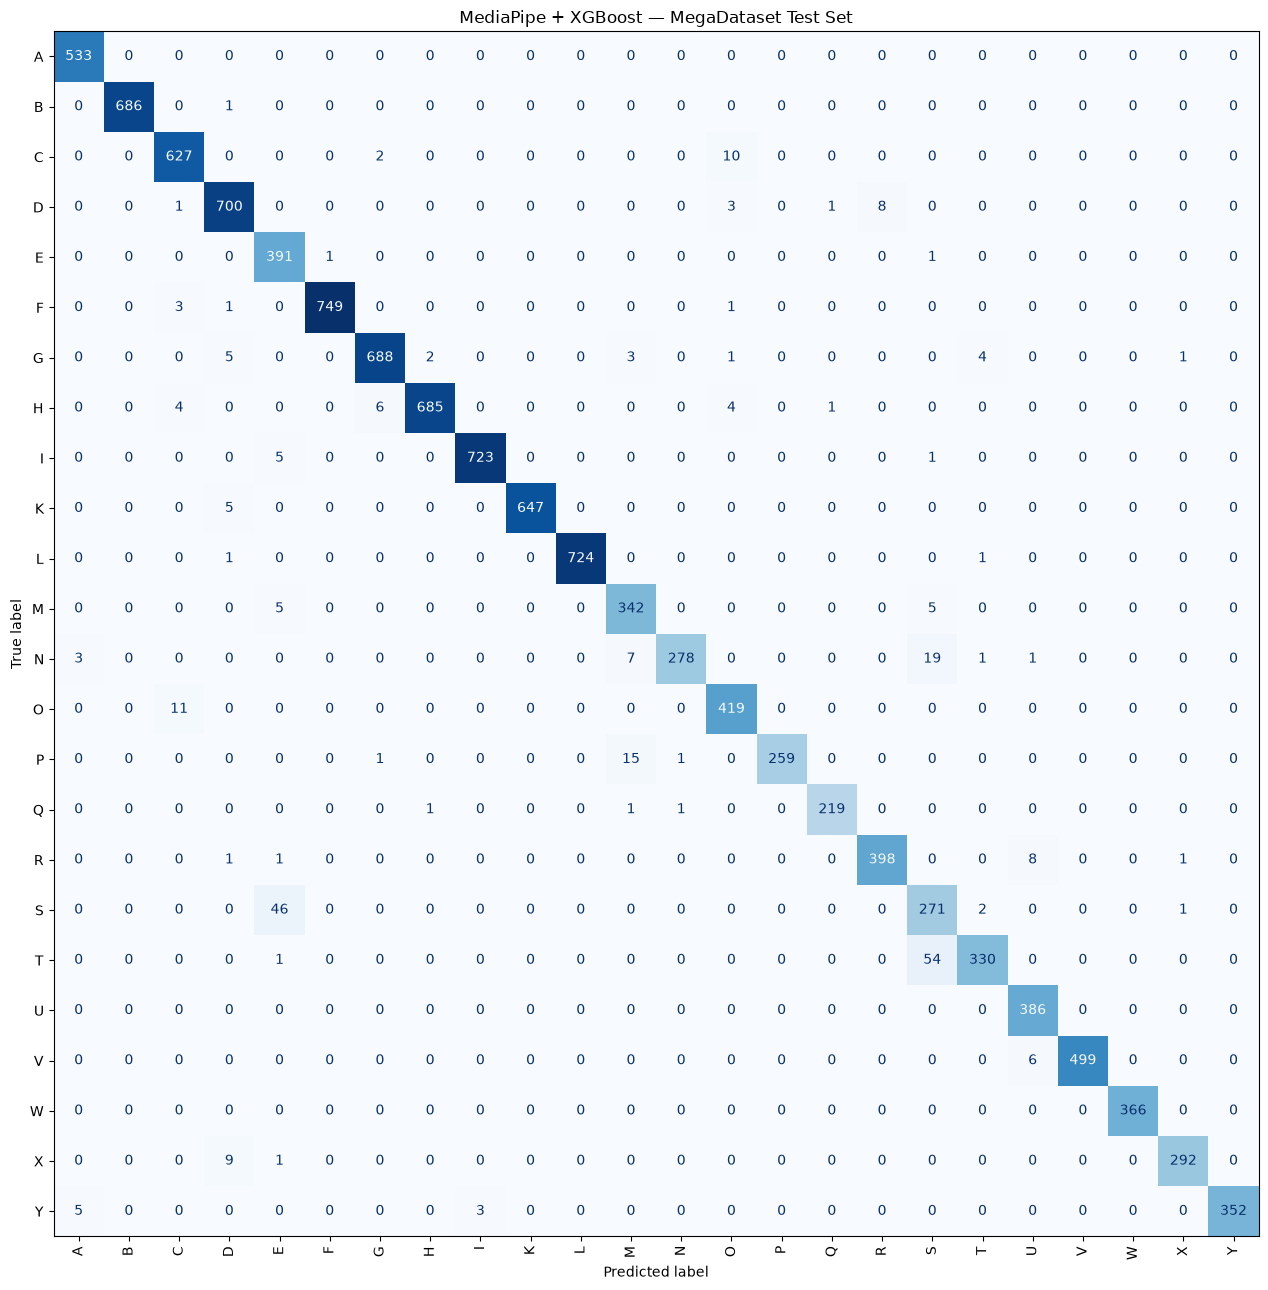

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrix = confusion_matrix(
    y_test,
    y_pred_test,
    labels=np.arange(24),
)

fig, ax = plt.subplots(figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=list(LETTERS),
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title("MediaPipe + XGBoost — MegaDataset Test Set")
plt.tight_layout()
plt.show()

In [57]:
from handspell.model_landmarks_training import extract_features
# Test on hard dataset

dataset_path = "../data/raw_data/A02_kaggle_ahmedkhanak/selected_gestures"
paths, labels = find_images(dataset_path)
features, failures = extract_features(paths)
y_pred_hard = classifier.predict(features)

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792536585.823815 6978534 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792536585.829261 6978536 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/36000 [00:00<?, ?it/s]

In [59]:
features.shape, y_pred_hard.shape, len(failures), len(paths)

((36000, 63), (36000,), 10312, 36000)

In [64]:
np.isnan(features[:,0])

array([False, False, False, ...,  True,  True,  True], shape=(36000,))

In [69]:
y_pred_hard[np.isnan(features[:,0])] = -1

In [65]:
labels

array([ 0,  0,  0, ..., 23, 23, 23], shape=(36000,))

In [79]:
np.array(y_pred_hard_nohands)

array([ 0,  0,  0, ..., 24, 24, 24], shape=(36000,))

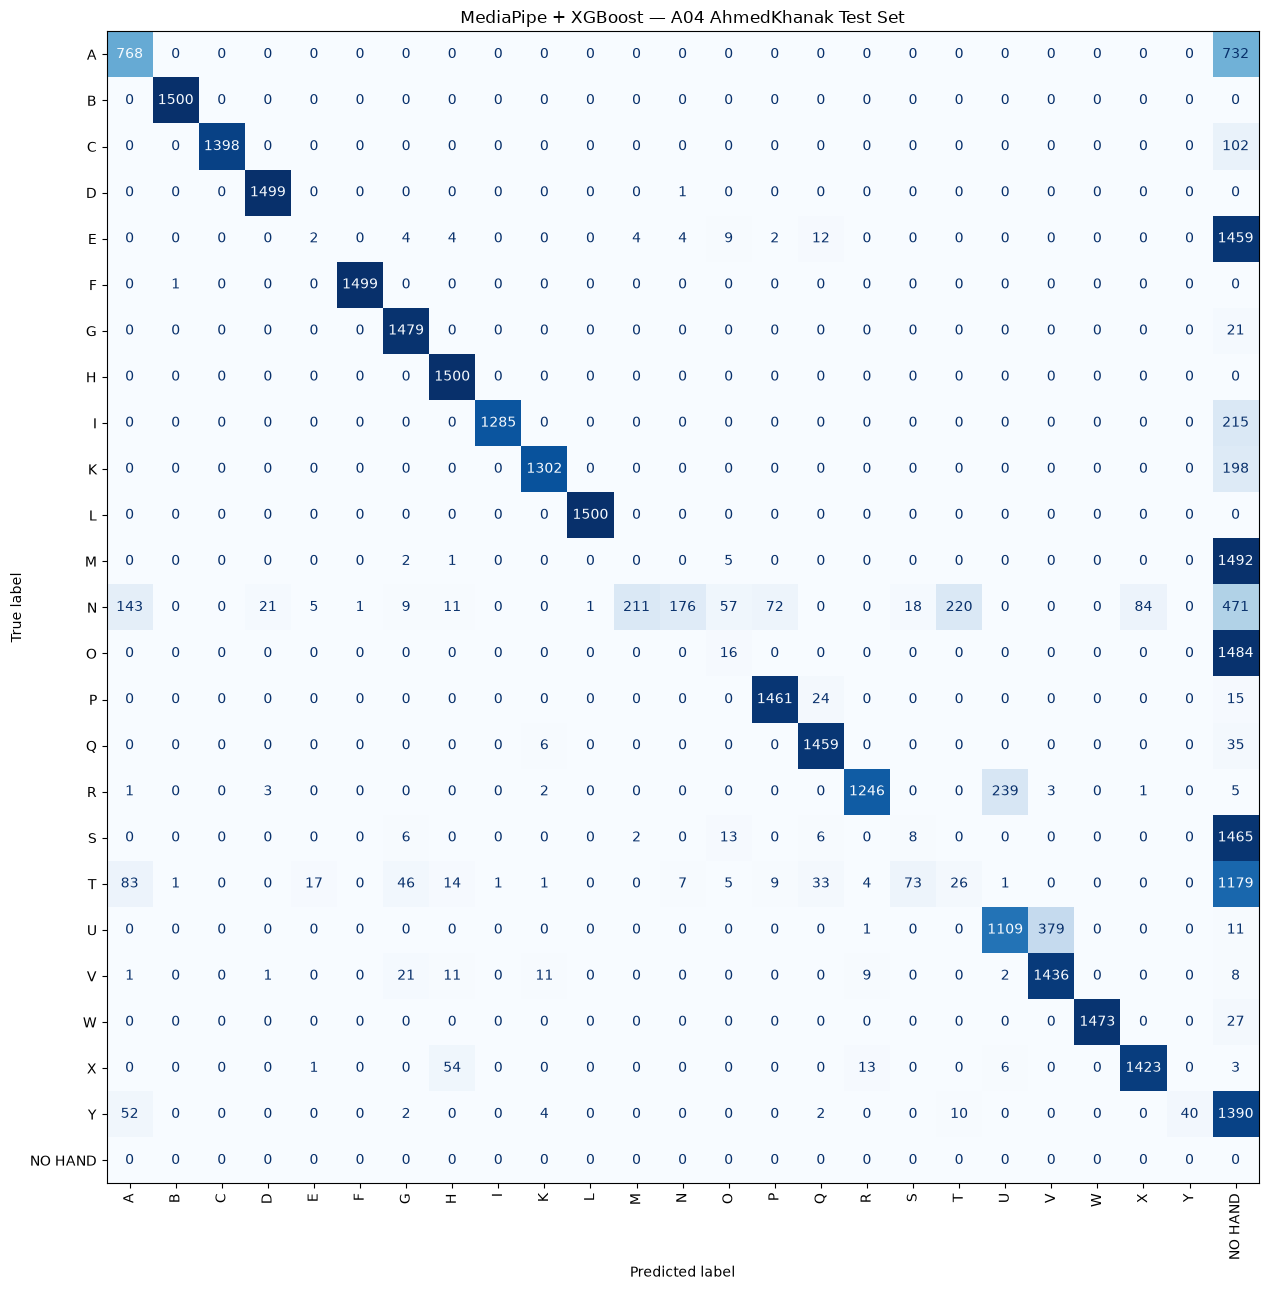

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

true_letters = [LETTERS[i] for i in labels]
y_pred_hard_nohands = np.array([li if not np.isnan(features[i,0]) else 24 for i, li in enumerate(y_pred_hard)])
# When no hand, set prediction to "NO HAND"


matrix = confusion_matrix(
    labels,
    y_pred_hard_nohands,
    #labels=list(LETTERS)+["NO HAND"],
)

fig, ax = plt.subplots(figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=list(LETTERS)+["NO HAND"],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title("MediaPipe + XGBoost — A04 AhmedKhanak Test Set")
plt.tight_layout()
plt.show()

In [ ]:
# Test on Mapping


# Train model on all data and save

classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=24,
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="merror",
    random_state=42,
    n_jobs=4,
)

In [52]:
classifier.fit(
    pd.concat([X_train, X_val, X_test]),
    pd.concat([y_train, y_val, y_test]),
)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [53]:
import joblib
joblib.dump(classifier, "../models/handspell_xgboost_megadata_v2.joblib")

['../models/handspell_xgboost_megadata_v2.joblib']